# Assignment 2 – Zero-Shot Image Classification with Transformers

In this assignment, you will apply a pre-trained vision–language transformer (e.g. CLIP) to perform **zero-shot** classification on the Fashion-MNIST dataset—classifying each image without any task-specific training. You will build on the concepts from Assignment 1 by comparing this “off-the-shelf” approach to the CNN you previously trained.

You will:
1. **Load** the Fashion-MNIST images using PyTorch instead of Keras.
2. **Run a zero-shot baseline** with simple text prompts to set a performance reference.
3. **Engineer improved prompts** and measure the resulting accuracy gains.
4. **Visualise image embeddings** with UMAP to inspect class separability.
5. **Conduct one mini-experiment** of your choice.
6. **Summarise findings** and reflect on strengths and weaknesses of zero-shot transformers versus a trained CNN.

# 1. Loading the Fashion-MNIST Dataset

As in assignment 1, we'll load the Fashion-MNIST dataset, but this time using `torchvision.datasets` to ensure compatibility with the `transformers` library. We will also load our model and processor from the `transformers` library.

The transformers library allows us to use pre-trained models like CLIP, which can perform zero-shot classification by leveraging the text prompts we provide. There are two key objects we will use: the `CLIPModel` for the model itself and the `CLIPProcessor` for preparing our images and text prompts.

Since we are not actually training a model in this assignment, we will set the CLIP model to evaluation mode. If the model is designed to utilize features like dropout or batch normalization, setting it to evaluation mode ensures that these features behave correctly during inference (prediction). Setting the model to evaluaton mode also tells PyTorch that we don't have to compute gradients, which can save memory and speed up inference.

In order to speed up processing, we will also move the model to an "accelerator" if available. This is typically a GPU, but modern MacBooks also have an "Apple Silicon" accelerator that can be used for inference, called MPS (Metal Performance Shaders). If you are using a MacBook with Apple Silicon, you can use the MPS device for faster processing.

In [4]:
# Uncomment and run if required
#!pip install transformers torchvision torch accelerate

import torch, transformers, torchvision, accelerate
print(torch.__version__, transformers.__version__)

2.15.0 5.23.0


In [5]:
from transformers import CLIPModel, CLIPProcessor
import torch

clip_model_name = "openai/clip-vit-base-patch32"
clip_model     = CLIPModel.from_pretrained(clip_model_name)
clip_processor = CLIPProcessor.from_pretrained(clip_model_name, use_fast=False)

# Set model to evaluation mode, as we are not training it
clip_model.eval()

# Check for accelerators
device = "cpu" # Default to CPU
if torch.cuda.is_available():
    device = "cuda" # Use GPU if available
elif torch.backends.mps.is_available():
    device = "mps"

clip_model.to(device)

print(f"Using device: {device}")

W1114 10:20:45.994000 97776 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[transformers] The `use_fast` parameter is deprecated and will be removed in a future version. Use `backend="torchvision"` instead of `use_fast=True`, or `backend="pil"` instead of `use_fast=False`.


Using device: mps


Now we are ready to load the testing set from Fashion-MNIST. We will use the `torchvision.datasets.FashionMNIST` class to load the dataset. We do not need to apply any transformations to the images, as the `CLIPProcessor` ensures any input images are in the format that the model is trained on.

You should:

- [ ] Use the `torchvision.datasets.FashionMNIST` class to load the *test* split of the dataset. Documentation is available [here](https://pytorch.org/vision/stable/generated/torchvision.datasets.FashionMNIST.html).
- [ ] Create a PyTorch `DataLoader` to iterate over the dataset in batches. Use a batch size of 16 and set `shuffle=True` to randomise the order of the images. You will also need to supply the provided `collate_clip` function to the `DataLoader collate_fn` argument to ensure the images are processed correctly. Documentation for `DataLoader` is available [here](https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader).

In [6]:
from torchvision import datasets
from torch.utils.data import DataLoader

import torchvision

CLASS_NAMES = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

def collate_clip(batch):
    imgs, labels = zip(*batch) # Unzip the batch into images and labels
    proc = clip_processor(images=list(imgs),
                        return_tensors="pt",
                        padding=True) # Process images with CLIPProcessor
    # Send pixel_values to GPU/CPU now; labels stay on CPU for metrics
    return proc["pixel_values"].to(device), torch.tensor(labels)

test_dataset = torchvision.datasets.FashionMNIST(root="./data", train=False, download=True)
test_loader = DataLoader(test_dataset,batch_size=16,shuffle=True,collate_fn=collate_clip)

If your code is correct, the following cell should show the first batch of images from the Fashion-MNIST dataset:

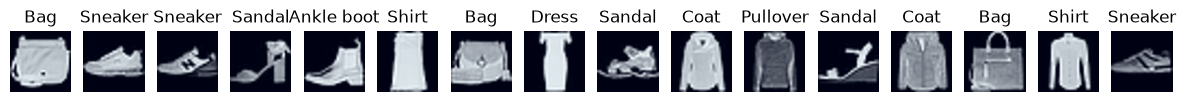

In [7]:
import matplotlib.pyplot as plt

# Display the first batch of images from `test_loader`

def show_batch(loader):
    images, labels = next(iter(loader))
    images = images.cpu()  # Move images to CPU for plotting
    # Renormalize to [0, 1] for visualization
    images = (images - images.min()) / (images.max() - images.min())
    _, axes = plt.subplots(1, len(images), figsize=(15, 5))
    for ax, img, label in zip(axes, images, labels):
        ax.imshow(img.permute(1, 2, 0))
        ax.set_title(CLASS_NAMES[label.item()])
        ax.axis('off')
    plt.show()

show_batch(test_loader)

We’re now ready to run our zero-shot classification baseline!

# Brief Introduction to Zero-Shot Classification

In Assignment 1, we followed the typical machine-learning pipeline: we trained a CNN on the Fashion-MNIST dataset, using labelled examples to update the model’s weights. While effective, that approach requires a curated, task-specific training set—a luxury you don’t always have in practice.

Zero-shot classification flips the script.  A large vision–language model (VLM) such as **CLIP** is first pre-trained on hundreds of millions of image–text pairs scraped from the web.  Because it learns *joint* visual–textual embeddings, the model can later solve new tasks simply by “measuring” how similar an image is to a **text prompt** that describes each candidate class—without seeing a single task-labelled example.

**How it works**  
1. Feed an image through CLIP’s vision encoder → **image feature**.  
2. Feed a textual prompt (e.g. “a photo of a sandal”) through CLIP’s text encoder → **text feature**.  
3. Compute cosine similarity between the image feature and every class’s text feature.  
4. Pick the class whose prompt is most similar.

For our first attempt, we’ll use the bare class names as prompts, e.g.:

- "T-shirt/top"
- "Trouser"

### You should:

- [ ] Build embeddings: use the `get_text_embeddings` helper function to create text embeddings for the class names.
- [ ] Run inference: use the `get_image_embeddings` helper function to create image embeddings.
- [ ] Compute cosine similarity: complete and use the `get_cosine_similarity` helper function to compute the cosine similarity between the image and text embeddings.
- [ ] Make predictions: use the `get_predictions` helper function to get the predicted class for each image in the batch.

Note that for normalized vectors like the ones we are using, cosine similarity is equivalent to the dot product. This means we can use the handy formula `cosine_similarity = vector_a @ vector_b.T` to compute the similarity between the image and text embeddings.

In [ ]:
#updates from slack

def get_text_embeddings(class_names: list[str]) -> torch.Tensor:
    """    Get text embeddings for the given class names using CLIP.
    Args:
        class_names (list[str]): List of class names to encode.
    Returns:
        torch.Tensor: Normalized text embeddings for the class names.
    """
    tokenized = clip_processor(text=class_names,
                               padding=True,
                               return_tensors="pt").to(device)
    
    with torch.no_grad():
        text_embeddings = clip_model.get_text_features(**tokenized)
    text_embeddings = text_embeddings.pooler_output
    text_feats = text_embeddings / text_embeddings.norm(dim=-1, keepdim=True)

    return text_feats

def get_image_embeddings(images: torch.Tensor) -> torch.Tensor:
    """    Get image embeddings for the given images using CLIP.
    Args:
        images (torch.Tensor): Batch of images to encode.
    Returns:
        torch.Tensor: Normalized image embeddings for the images.
    """
    with torch.no_grad():
        image_embeddings = clip_model.get_image_features(pixel_values=images)
    image_embeddings = image_embeddings.pooler_output
    image_feats = image_embeddings / image_embeddings.norm(dim=-1, keepdim=True)

    return image_feats
    

In [9]:
import numpy as np

def get_cosine_similarity(image_feats: torch.Tensor, text_feats: torch.Tensor) -> np.ndarray:
    """
    Compute cosine similarity between image features and text features.
    Args:
        image_feats (torch.Tensor): Image features of shape (N, D).
        text_feats (torch.Tensor): Text features of shape (M, D).
    Returns:
        numpy.ndarray: Cosine similarity matrix of shape (N, M), where N is the number of images and M is the number of text prompts.
    """
    image_feats = image_feats.cpu()  # Ensure image features are on CPU
    text_feats = text_feats.cpu()    # Ensure text features are on CPU

    # Compute cosine similarity, which is the dot product of normalized vectors
    return (image_feats @ text_feats.T).numpy() # Complete

def get_predictions(similarity: np.ndarray) -> np.ndarray:
    """
    Get predictions based on cosine similarity scores.
    Args:
        similarity (numpy.ndarray): Cosine similarity matrix of shape (N, M), where N is the number of images and M is the number of text prompts.
    Returns:
        numpy.ndarray: Predicted class indices for each image, shape (N,).
    """
    # Get the index of the maximum similarity for each image
    return similarity.argmax(axis=1) # Complete

With these functions complete, you are ready to run the zero-shot classification baseline. Complete the code to follow these steps:

- [ ] Build text embeddings for the class names using the `get_text_embeddings` function (this only needs to be done once).
- [ ] For each batch of images:
    - [ ] Get image embeddings using the `get_image_embeddings` function.
    - [ ] Compute cosine similarity between the image and text embeddings using the `get_cosine_similarity` function.
    - [ ] Save the predictions so that we can build a confusion matrix later.
- [ ] Report the accuracy of the predictions and the confusion matrix using the `accuracy_score` and `confusion_matrix` functions from `sklearn.metrics`.

/var/folders/t3/9yyp1tp50991svz4njl3j7880000gn/T/ipykernel_97776/2154316461.py:16: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  y_true.extend(np.array(labels))


Zero-shot accuracy: 62.40%


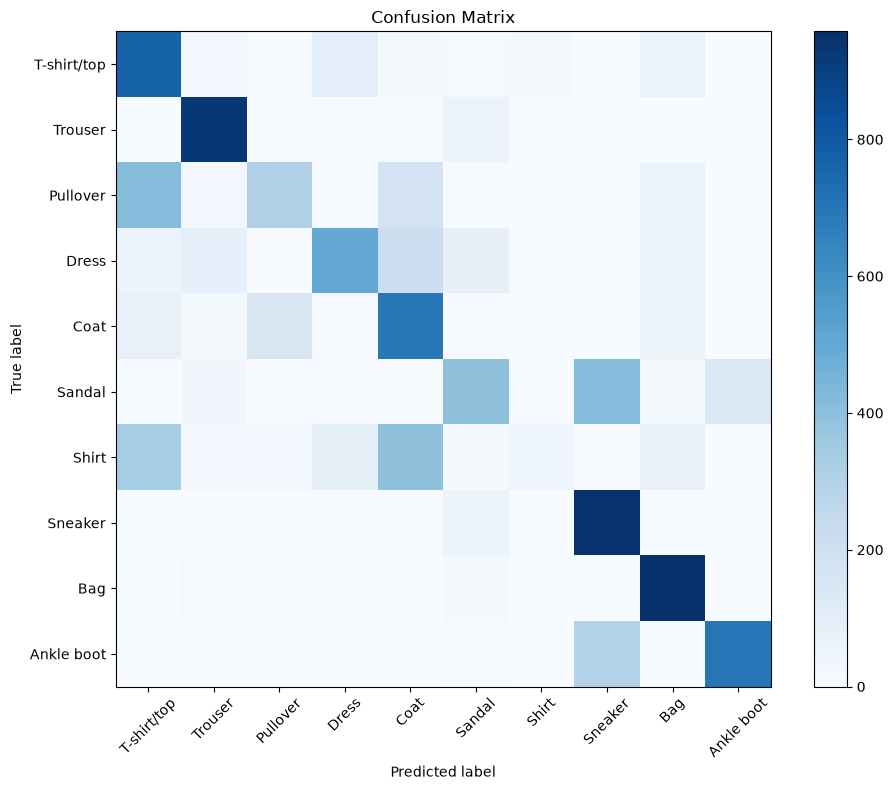

In [13]:
from sklearn.metrics import accuracy_score, confusion_matrix
                
text_feats = get_text_embeddings(CLASS_NAMES)      


y_true, y_pred = [], []

for pixel_values, labels in test_loader:
    pixel_values = pixel_values.to(device)

    image_feats = get_image_embeddings(pixel_values)
    similarity = get_cosine_similarity(image_feats, text_feats)
    preds = get_predictions(similarity)

    y_pred.extend(preds)
    y_true.extend(np.array(labels))


# Report the accuracy of the predictions

accuracy = accuracy_score(y_true, y_pred)
print(f"Zero-shot accuracy: {accuracy * 100:.2f}%")

# Report the confusion matrix
def plot_confusion_matrix(y_true, y_pred, class_names):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title('Confusion Matrix')
    plt.colorbar()
    tick_marks = np.arange(len(class_names))
    plt.xticks(tick_marks, class_names, rotation=45)
    plt.yticks(tick_marks, class_names)
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.tight_layout()
    plt.show()

plot_confusion_matrix(y_true, y_pred, CLASS_NAMES)

Reflection: Consider the results. How does the performance of this zero-shot baseline compare to the CNN you trained in Assignment 1? What are the strengths and weaknesses of this approach?

The performance is much less with zeroshot and yes this is a weakness but you also have to look at it from the perspective it was with no training whatsoever.

CNN uses training of 48,000 labelled exams. There are no missing categories - makes prediction on classes and was scoring in the 80s. But this requires data. If you want to improve CNN, you have to make changes, add layers do various experiments and play with your training parameters. Its data intensive - you need to collect more data. CNN is not easy to tweak on the fly - in fact its not even possible. You make a change, you have to re-train.

We also noticed that with Zero-shot - if you added more words to the prompt, it got distracted and diverted. This is an obvious weakness. However with Zero-shot, you simply can improve performance by modifying your prompt - but of course you need to be careful. The good news here is its on the fly - no need to add more data.

I think for general ideas Zero Shot is better and if you really want to dig deeep and be more accurate off the bat with a larger data set you go with CNN.


## Improving Zero-Shot Classification with Prompt Engineering

In the previous section, we directly used the class names as text prompts for zero-shot classification. However, we can often improve performance by crafting more descriptive prompts that better capture the visual characteristics of each class. For example, instead of just "T-shirt/top", we could use "a photo of a T-shirt" or "a photo of a top". This additional context can help the model make more accurate predictions.

In this section, we will experiment with more detailed prompts for each class to see if we can improve the zero-shot classification performance. You should:

- [ ] Create a list of improved prompts for each class. For example, instead of just "T-shirt/top", you could use "a photo of a T-shirt" or "a photo of a top".
- [ ] Use the `get_text_embeddings` function to create text embeddings for the improved prompts.
- [ ] Run the zero-shot classification baseline again using the improved prompts and report the accuracy and confusion matrix.

Note: Take advantage of the confusion matrix above. If two classes are often confused, consider how you might improve the prompts to help the model distinguish them better.

The aim for this section is for you to improve the performance of the model. However, if you find that the performance does not improve significantly, you can still reflect on the process and consider how you might further refine the prompts with more effort.

/var/folders/t3/9yyp1tp50991svz4njl3j7880000gn/T/ipykernel_97776/2342071992.py:35: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  y_true2.extend(np.array(labels))


Zero-shot accuracy: 58.97%


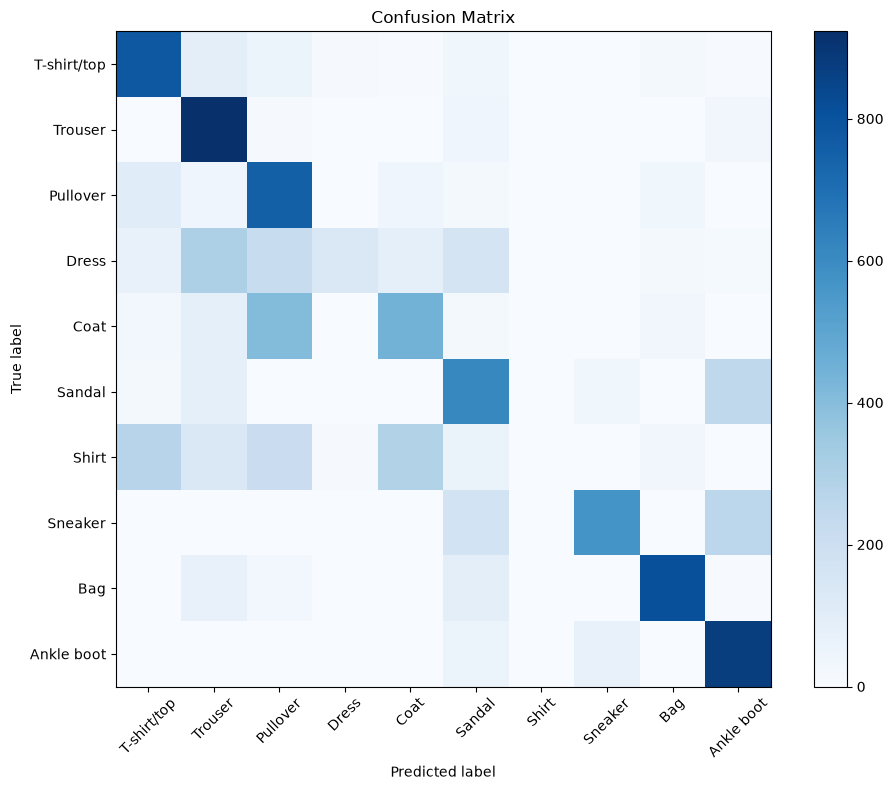

In [26]:
from torchvision import datasets
from torch.utils.data import DataLoader

import torchvision

PROMPT_CLASS_NAMES = [
    "The photo has T-shirt/top",
    "The Trouser is pictured",
    "She is wearing a Pullover in the photo",
    "He wanted a Dress for halloween. The dress is in the picture",
    "This Coat is for sale in the photo",
    "The Sandal was used in the beach photo",
    "The Shirt is not allowed. It is in the photo",
    "The kid wore a Sneaker in the photo",
    "This Bag is not allowed. It is in the photo",
    "He broke his ankle playing football. here is the photo of the Ankle boot"
]


from sklearn.metrics import accuracy_score, confusion_matrix

                
text_feats_bad = get_text_embeddings(PROMPT_CLASS_NAMES)      

y_true2, y_pred2 = [], []

for pixel_values, labels in test_loader:
    pixel_values = pixel_values.to(device)

    image_feats = get_image_embeddings(pixel_values)
    similarity = get_cosine_similarity(image_feats, text_feats_bad)
    preds = get_predictions(similarity)

    y_pred2.extend(preds)
    y_true2.extend(np.array(labels))


# Report the accuracy of the predictions

accuracy = accuracy_score(y_true2, y_pred2)
print(f"Zero-shot accuracy: {accuracy * 100:.2f}%")

# Report the confusion matrix
def plot_confusion_matrix(y_true, y_pred, class_names):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title('Confusion Matrix')
    plt.colorbar()
    tick_marks = np.arange(len(class_names))
    plt.xticks(tick_marks, class_names, rotation=45)
    plt.yticks(tick_marks, class_names)
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.tight_layout()
    plt.show()

plot_confusion_matrix(y_true2, y_pred2, CLASS_NAMES)

/var/folders/t3/9yyp1tp50991svz4njl3j7880000gn/T/ipykernel_97776/1237478584.py:34: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  y_true.extend(np.array(labels))


Zero-shot accuracy: 66.40%


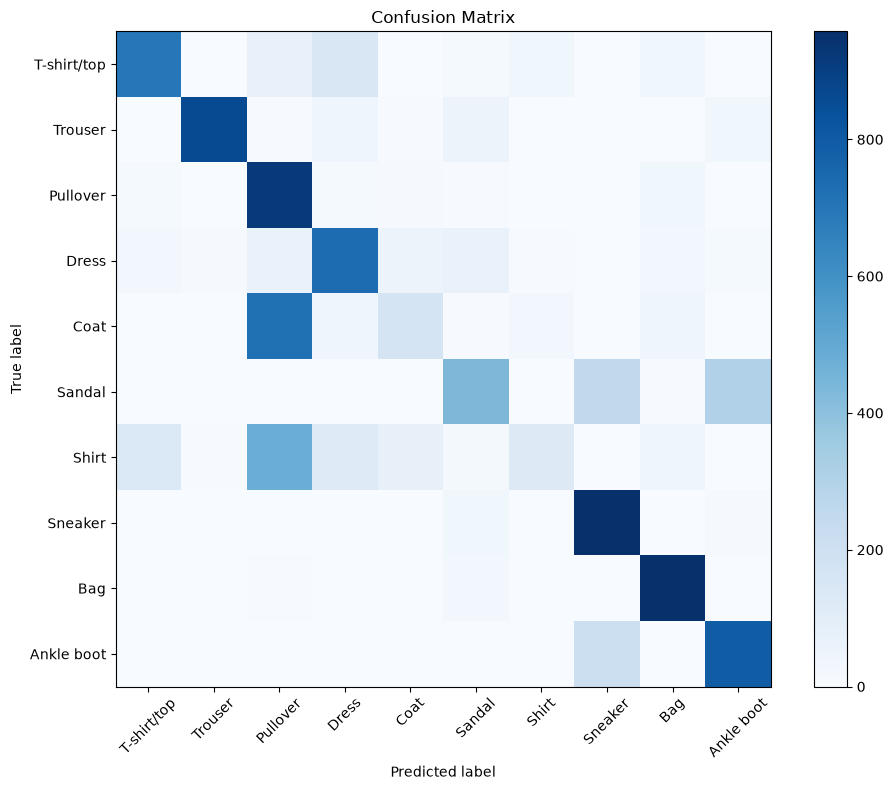

In [25]:
from torchvision import datasets
from torch.utils.data import DataLoader

import torchvision

BETTER_PROMPTS_CLASS = [
    "a photo of a T-shirt/top",
    "a photo of a pair of trousers",
    "a photo of a pullover sweater",
    "a photo of a dress",
    "a photo of a coat",
    "a photo of a sandal",
    "a photo of a button-up shirt",
    "a photo of a sneaker",
    "a photo of a bag",
    "a photo of an ankle boot",
]

from sklearn.metrics import accuracy_score, confusion_matrix

                
text_feats = get_text_embeddings(BETTER_PROMPTS_CLASS)      

y_true, y_pred = [], []

for pixel_values, labels in test_loader:
    pixel_values = pixel_values.to(device)

    image_feats = get_image_embeddings(pixel_values)
    similarity = get_cosine_similarity(image_feats, text_feats)
    preds = get_predictions(similarity)

    y_pred.extend(preds)
    y_true.extend(np.array(labels))


# Report the accuracy of the predictions

accuracy = accuracy_score(y_true, y_pred)
print(f"Zero-shot accuracy: {accuracy * 100:.2f}%")

# Report the confusion matrix
def plot_confusion_matrix(y_true, y_pred, class_names):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title('Confusion Matrix')
    plt.colorbar()
    tick_marks = np.arange(len(class_names))
    plt.xticks(tick_marks, class_names, rotation=45)
    plt.yticks(tick_marks, class_names)
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.tight_layout()
    plt.show()

plot_confusion_matrix(y_true, y_pred, CLASS_NAMES)

Reflection: How did your detailed prompts affect the zero-shot classification performance? Did you see a significant improvement compared to the baseline? What insights did you gain about the model's understanding of the classes? Do you think that with more effort you could further improve the performance? If so, how?

So I did two experiments. When I first did my initial set of prompts I got worse performance. I wondered why - I had the name but it seems my prompts were out of context. This shows me that prompt engineering doesnt automatically make it better or improve things. I guess the kind or tyoe of prompt matters most.  It seems I was too wordy and the embedding got treated differently.  It seems my extra words dragged it away form the clothing item. I said broke his ankle playing football - but this isnt a photo of the ankle but rather a sports injury.  I also had one prompt that said "is not allowed" this causes it think the image doesnt have it.

So I did the experiement a second time using the prompts you gave in your example. This was more straight forward and said a photo of a coat or a photo of an ankle boot. This gave better results at around 66.40% vs 62%

Not a significant improvement but marginal - much better than my wordy story prompts that caused diversions.

In terms of insights - the model seems to have a general understanding of the words and what the imaging looks like. Even with the zero prompt and using embeddings - and using basic words it only improved to 66%. So its using predictions of a point in space and finding the general area of where it might land. To improve you could use bagging with your prompts and establish different random sets. You then take the avg and normalize.  You could also give additional descriptions to the classes. This would help with matching what is in the prompt. In addition, you could the style of image in the prompt. These are just black and white images and not colour photos.



## Visualizing Image Embeddings with UMAP

To better understand how the model perceives the different classes, we can visualize the image embeddings using UMAP (Uniform Manifold Approximation and Projection). UMAP is a dimensionality reduction technique that helps us see how similar or dissimilar the embeddings are in a lower-dimensional space.

By visualizing the embeddings, we can gain insights into how well the model can distinguish certain images, even without considering the text prompts. This can help us identify clusters of similar images and see if there are any overlaps between classes.

You should:

- [ ] Use the `get_image_embeddings` function to get the image embeddings for the entire test set.
- [ ] Use UMAP to reduce the dimensionality of the image embeddings to 2D.
- [ ] Plot the 2D embeddings, coloring each point by its true class label.

You may need to install the `umap-learn` library if you haven't already. You can do this by running `pip install umap-learn`.

In [ ]:
# Uncomment the following line to install UMAP if you haven't already
# !pip install umap-learn

/var/folders/t3/9yyp1tp50991svz4njl3j7880000gn/T/ipykernel_97776/1838538437.py:13: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  all_labels.extend(np.array(labels))


(10000, 512) (10000,)


/Users/abhatia/MLF2/deep_learning/deep-learning-env/lib/python3.11/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Users/abhatia/MLF2/deep_learning/deep-learning-env/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


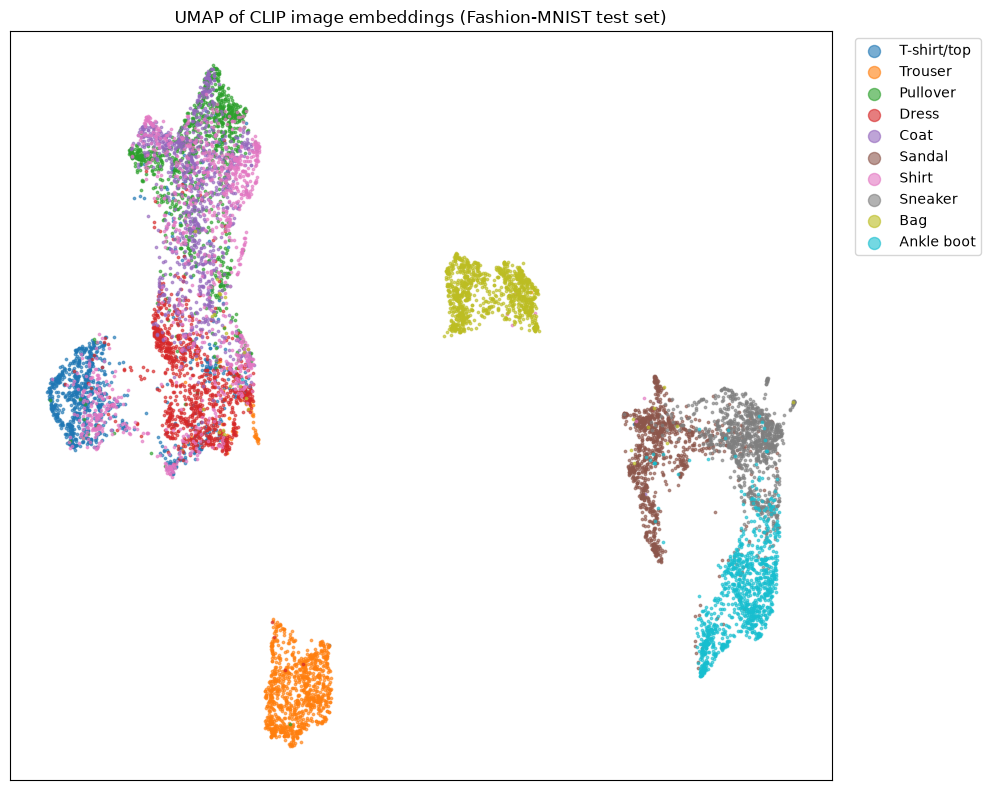

In [ ]:
from umap import UMAP

# ------------------------------------------------------------
# 1. Collect image embeddings
# ------------------------------------------------------------
all_img_emb = []
all_labels  = []

for pixel_values, labels in test_loader:
    pixel_values = pixel_values.to(device)
    emb = get_image_embeddings(pixel_values)
    all_img_emb.append(emb.cpu())
    all_labels.extend(np.array(labels))

all_img_emb = torch.cat(all_img_emb).numpy() 
all_labels  = np.array(all_labels)             
print(all_img_emb.shape, all_labels.shape)


# ------------------------------------------------------------
# 2. Fit UMAP
# ------------------------------------------------------------
umap_model = UMAP(n_components=2, random_state=42)
img_2d = umap_model.fit_transform(all_img_emb)  

# ------------------------------------------------------------
# 3. Plot coloured by ground-truth label
# ------------------------------------------------------------
plt.figure(figsize=(10, 8))
for i, name in enumerate(CLASS_NAMES):
    mask = all_labels == i
    plt.scatter(img_2d[mask, 0], img_2d[mask, 1], s=3, alpha=0.6, label=name)

plt.legend(markerscale=5, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.title("UMAP of CLIP image embeddings (Fashion-MNIST test set)")
plt.xticks([]); plt.yticks([])
plt.tight_layout()
plt.show()

The UMAP embeddings allow us to see how separable or non-separable different classes are with our specific model. If two specific images are very similar, then they will be placed near each other on this graph. 

Reflection: Do you notice any challenges in distinguishing images based on this figure? Are there any types of clothing in the dataset which the model has no trouble distinguishing from the others?


Overall we clearly see a pattern that emerges. You see that bags and trousers are clearly distinguished and are a part from each other. They are in their own separate regions and there is no other foreign clusters near by.  What's interesting is that the model generally is able to group items that would be related to the upper body vs the lower body.  You do see there is separation between shoes, shirts and jackets.  However, if you take a look at the region to the left, you see the model does have issues identifying pullovers, coats and shirts (you see clear overlap) So this helps explain why when we modified text in our zero shot prompts, we didnt see such a huge improvement. The model is having a hard time telling them apart visually.

You do see some better performance with separating sandals, sneakers and ankle boots. It could be that visually we can tell them apart and its just the text descriptions that may need to be improved.

It seems that to improve pullover, coats and shirts, we may need to retrain with better clothing images. The data was broad internet image data. We may need to consider better quality imaging with more details to help clasify which is with.




## Mini-Experiment

In this section, you will conduct a mini-experiment of your choice to further explore the capabilities of zero-shot classification with transformers. This can be anything you'd like, but here are some ideas to get you started.

### A. Alternative Model

So far we have been utilizing OpenAI's CLIP model for zero-shot classification. However, there are many other vision–language models available in the `transformers` library that you can experiment with. For example, there are larger CLIP models such as [clip-vit-large-patch14](https://huggingface.co/openai/clip-vit-large-patch14), and open-source versions such as [laion/CLIP-ViT-B-32-laion2B-s34B-b79K](https://huggingface.co/laion/CLIP-ViT-B-32-laion2B-s34B-b79K). You can also search huggingface [here](https://huggingface.co/models?sort=trending&search=clip) to find other models that might be suitable for zero-shot classification.

You can try using a different model to see if it improves the zero-shot classification performance. You should:
- [ ] Load a different model and processor from the `transformers` library.
- [ ] Run the zero-shot classification baseline with the new model and report the accuracy and confusion matrix.
- [ ] Reflect on the performance of the new model compared to the original CLIP model
  - How does the new model perform compared to the original CLIP model?
  - Do you notice any differences in the types of errors made by the new model?

### B. Multiple-Description Classification

Another interesting experiment is to explore multiple-description classification. *This involves providing multiple text prompts for each class, allowing the model to choose the most relevant one. For example, instead of just "T-shirt/top", you could provide "a photo of a T-shirt", "a photo of a top", and "a photo of a shirt". This can help the model better understand the class and increases the likelihood of a correct prediction. You should:

- [ ] Create a list of multiple prompts for each class.
- [ ] Use the `get_text_embeddings` function to create text embeddings for the multiple prompts.
- [ ] Run the zero-shot classification baseline again using the multiple prompts and report the accuracy and confusion matrix.
- [ ] Consider the model to be correct if it guesses *any* of the prompts belonging to the correct class.

### C. Top-K Classification

In some classification tasks, it can be useful to consider if the right answer is among the top K (e.g. top 3) predictions. This can be particularly useful in cases where the model is uncertain or when there are multiple similar classes. You should:

- [ ] Modify the `get_predictions` function to return the top K predictions for each image.
- [ ] Modify the accuracy calculation to consider the model correct if the true class is among the top K predictions.
- [ ] Report the accuracy and confusion matrix for the top K predictions. Report at least two different values of K (e.g. K=2 and K=4).

### D. Other Ideas

You are welcome to come up with your own mini-experiment! Explain your idea in the report and implement it. Did it work as you expected? What did you learn from it?

In [ ]:
"""Multi-Description Classification

The process will be to create the multi-prompts and treat them as a 2D-Array for extraction. This needs to the case as each
class has to serve as its own pointer to a list of prompts.  We have 10 classes, and each class will have 4 different
prompts. 40 prompts in total

"""

MULTI_PROMPTS = [
    # 0 T-shirt/top
    ["a photo of a t-shirt", "a short-sleeved t-shirt", "a black and white photo of a t-shirt", "a plain top"],
    # 1 Trouser
    ["a photo of a pair of trousers", "a pair of pants", "a black and white photo of trousers", "a pair of jeans"],
    # 2 Pullover
    ["a photo of a pullover sweater", "a knitted sweater", "a long-sleeved jumper", "a black and white photo of a sweater"],
    # 3 Dress
    ["a photo of a dress", "a woman's dress", "a long dress", "a black and white photo of a dress"],
    # 4 Coat
    ["a photo of a coat", "a long winter coat", "a jacket with a zipper", "a black and white photo of a coat"],
    # 5 Sandal
    ["a photo of a sandal", "an open-toed sandal", "a sandal with straps", "a black and white photo of a sandal"],
    # 6 Shirt
    ["a photo of a button-up shirt", "a collared shirt", "a long-sleeved dress shirt", "a black and white photo of a shirt"],
    # 7 Sneaker
    ["a photo of a sneaker", "a running shoe", "a low-top sneaker", "a black and white photo of a sneaker"],
    # 8 Bag
    ["a photo of a bag", "a handbag", "a purse", "a black and white photo of a bag"],
    # 9 Ankle boot
    ["a photo of an ankle boot", "a leather boot", "a boot with a heel", "a black and white photo of an ankle boot"],
]

# Like we did previously we need a list of strings. Of course as per the above we have a list within a list.
# Take multi-prompts, iterate through them and store it in one array. Then we take each prompt and identify which class
# they belong to.

flat_prompts = []
prompt_to_class = []

#As per the previous examples, we will need a for loop - but this time a for loop within a for loop

for class_idx, prompts in enumerate(MULTI_PROMPTS):

    # Loop over each individual prompt string for this class.
    for prompt in prompts:

        
        flat_prompts.append(prompt)

        
        prompt_to_class.append(class_idx)


prompt_to_class = np.array(prompt_to_class)

# Normalize prompt
text_feats = get_text_embeddings(flat_prompts)

# ensuring it is correct.
print(len(flat_prompts))      
print(text_feats.shape)       
print(prompt_to_class)        


40
torch.Size([40, 512])
[0 0 0 0 1 1 1 1 2 2 2 2 3 3 3 3 4 4 4 4 5 5 5 5 6 6 6 6 7 7 7 7 8 8 8 8 9
 9 9 9]


/var/folders/t3/9yyp1tp50991svz4njl3j7880000gn/T/ipykernel_97776/2565959485.py:37: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  y_true.extend(np.array(labels))


Multi-description zero-shot accuracy: 63.31%


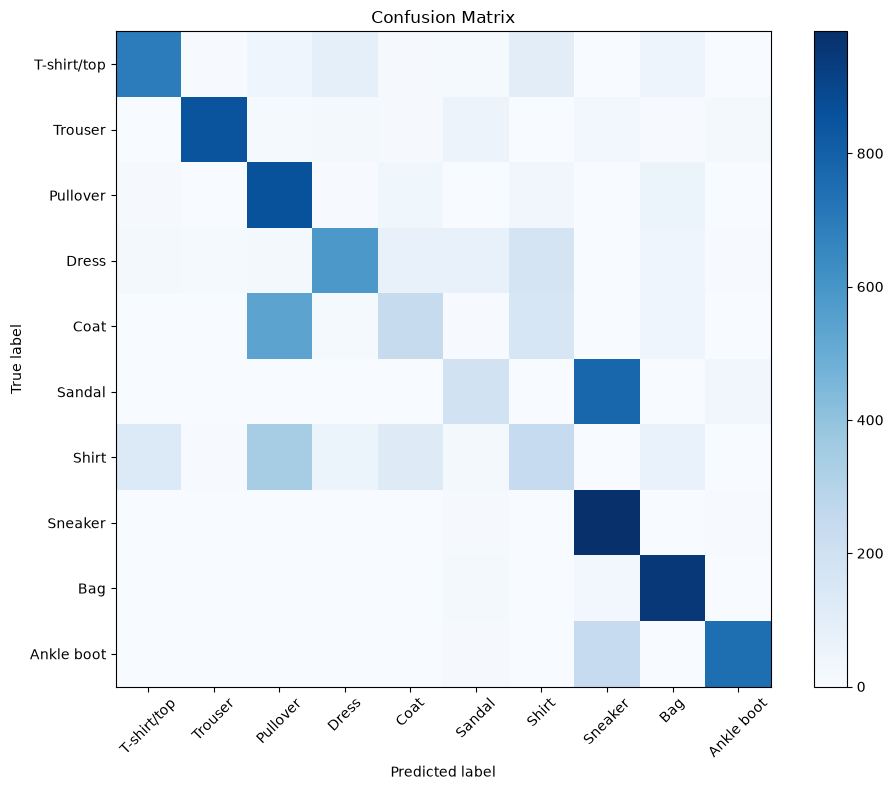

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix

# Empty lists to collect results across all batches.
# After the loop, each will hold 10,000 entries (one per test image),
# in matching order: y_true[i] and y_pred[i] are for the same image.
# I did get help from google and the previous examples.

y_true, y_pred = [], []

for pixel_values, labels in test_loader:

    # Move the images to mydevice
    pixel_values = pixel_values.to(device)

    # Normalize Run the images through CLIP's image encoder.
    image_feats = get_image_embeddings(pixel_values)

    # Compare every image to every prompt. text_feats is what we have established above.

    similarity = get_cosine_similarity(image_feats, text_feats)

    # For each image (each row), find the column with the highest similarity.
    # Result: 16 numbers between 0 and 39 -> WHICH PROMPT matched best.
    # These are prompt indices
    prompt_preds = get_predictions(similarity)

    # Translate prompt indices into class numbers using our lookup array.
    # This is what makes any prompt of the right class count as correct:
    # "an open-toed sandal" and "a photo of a sandal" both map to class 5.
    preds = prompt_to_class[prompt_preds]

    # Add this batch's 16 predictions to the overall list.
    # extend (not append) adds them as 16 separate items, not one list-in-a-list.
    y_pred.extend(preds)

    # Add the 16 true labels. np.array() makes sure they're plain numbers,
    # whether collate_clip returned them as a tensor or a list.
    y_true.extend(np.array(labels))

# Report the accuracy of the predictions:
# the fraction of images where y_pred matches y_true, across all 10,000.
accuracy = accuracy_score(y_true, y_pred)
print(f"Multi-description zero-shot accuracy: {accuracy * 100:.2f}%")

# Report the confusion matrix.
plot_confusion_matrix(y_true, y_pred, CLASS_NAMES)

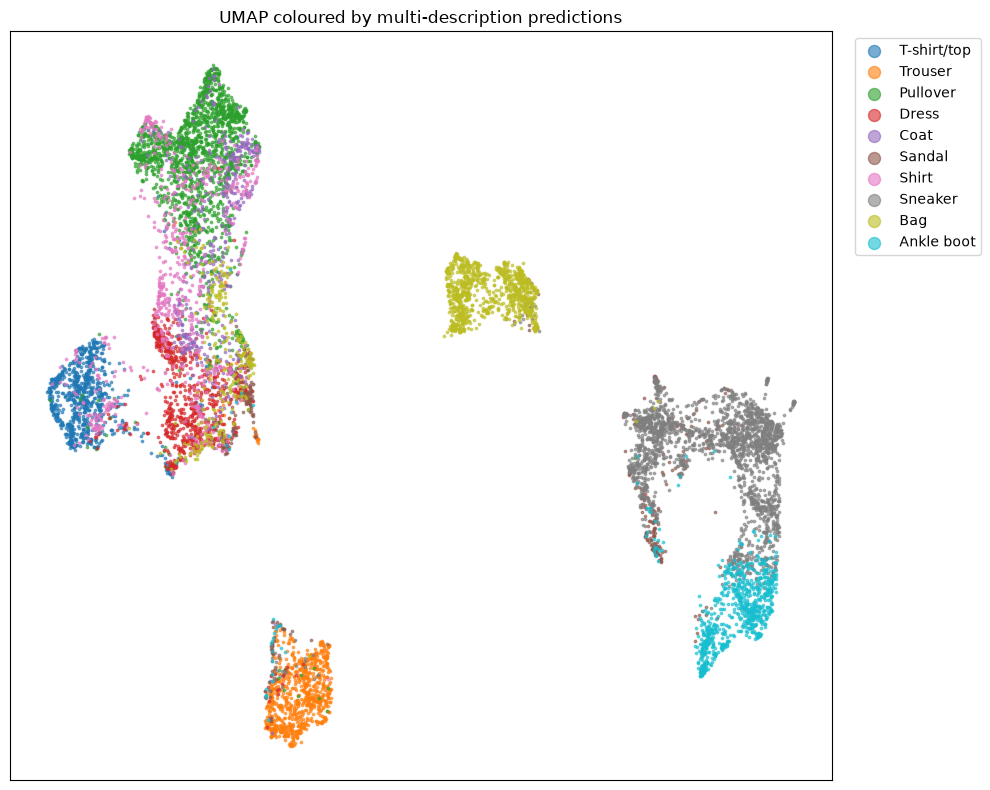

In [48]:
# So like we did for the Zero Shot prompting, we can re-use UMAP here to see how it looks. The difference is 
# We use the new text embeddings from the mutli-prompt

similarity = get_cosine_similarity(torch.from_numpy(all_img_emb), text_feats)
multi_preds = prompt_to_class[get_predictions(similarity)]

plt.figure(figsize=(10, 8))
for i, name in enumerate(CLASS_NAMES):
    mask = multi_preds == i
    plt.scatter(img_2d[mask, 0], img_2d[mask, 1], s=3, alpha=0.6, label=name)

plt.legend(markerscale=5, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.title("UMAP coloured by multi-description predictions")
plt.xticks([]); plt.yticks([])
plt.tight_layout()
plt.show()

In [49]:
# This was just for testing - I wanted to see how the predictions performed.

prompt_preds = get_predictions(similarity)
wins = np.bincount(prompt_preds, minlength=len(flat_prompts))

for prompt, cls, count in zip(flat_prompts, prompt_to_class, wins):
    print(f"{count:5d}  [{CLASS_NAMES[cls]}]  {prompt}")

   81  [T-shirt/top]  a photo of a t-shirt
  696  [T-shirt/top]  a short-sleeved t-shirt
   80  [T-shirt/top]  a black and white photo of a t-shirt
    1  [T-shirt/top]  a plain top
  308  [Trouser]  a photo of a pair of trousers
    0  [Trouser]  a pair of pants
  566  [Trouser]  a black and white photo of trousers
    0  [Trouser]  a pair of jeans
 1553  [Pullover]  a photo of a pullover sweater
    0  [Pullover]  a knitted sweater
  259  [Pullover]  a long-sleeved jumper
    3  [Pullover]  a black and white photo of a sweater
  329  [Dress]  a photo of a dress
  334  [Dress]  a woman's dress
   97  [Dress]  a long dress
   14  [Dress]  a black and white photo of a dress
   11  [Coat]  a photo of a coat
    0  [Coat]  a long winter coat
  140  [Coat]  a jacket with a zipper
  339  [Coat]  a black and white photo of a coat
   28  [Sandal]  a photo of a sandal
  212  [Sandal]  an open-toed sandal
    0  [Sandal]  a sandal with straps
  158  [Sandal]  a black and white photo of a sandal

In [ ]:
# This was just for testing - I wanted to see how the predictions performed.
# I wanted to take a closer look at a prompt that seemed to be closer to more images than expected

# So in this example we see that we have 721 correct - but in total 832 were wrong
# In this situation there was confusion between pullover, Coat, and shirts. These
# classes overlap in the image embeddings - so this promot captured all of them

import pandas as pd

running_idx = flat_prompts.index("a photo of a pullover sweater")
mask = prompt_preds == running_idx                      # images won by this prompt
pd.Series(np.array(CLASS_NAMES)[all_labels[mask]]).value_counts()

Pullover       721
Coat           476
Shirt          303
T-shirt/top     31
Dress           18
Trouser          3
Bag              1
Name: count, dtype: int64

In [51]:
running_idx = flat_prompts.index("a running shoe")
mask = prompt_preds == running_idx                      # images won by this prompt
pd.Series(np.array(CLASS_NAMES)[all_labels[mask]]).value_counts()

Sandal         771
Sneaker        672
Ankle boot     129
Bag             28
Trouser         27
Dress            2
T-shirt/top      1
Name: count, dtype: int64

### Short Report

In this section, you will write a short report summarizing your findings from the mini-experiment. The report should include the following sections:

- **Introduction**: Briefly describe the mini-experiment you conducted and its objectives.
- **Methodology**: Explain the steps you took to conduct the experiment, including any modifications you made to the code or model.
- **Results**: Present the results of your experiment.
- **Discussion**: Reflect on the performance of the model and the implications of your findings. Consider the strengths and weaknesses of zero-shot transformers versus a trained CNN.

Introduction:
I decided to go with Option B: Multiple-Description Classification.

The objective was to use multiple descriptions per class to improve the likelihood of a correct prediction. Quite simply, I used 4 prompts per class across 10 classes for a total of 40 prompts. The idea was to give the model different wordings, giving it more ways to recognize each item. As per the instructions, a prediction counted as correct if the image matched any of the prompts belonging to its true class.

Methodology:
As mentioned above, I created 4 prompts per class for a total of 40 prompts. These built on the plain baseline captions by adding more specific descriptions and hints about the style of the image.

Since `get_text_embeddings` takes a single list (as we saw in the zero-shot example), I flattened the 40 prompts into one list and created a matching lookup array to track which class each prompt belonged to. From there, the pipeline followed the same loop as the baseline: embed all 40 prompts, embed the batch of images, compute cosine similarity against all 40 prompts, and pick the closest match. The lookup array then mapped the winning prompt back to its predicted class.

The only thing that changed was the prompts—I used the exact same test set, images, and model. To dig into the behavior, I also counted how often each prompt won, checked the true classes of the images captured by the top prompts, and generated a UMAP plot of the image embeddings colored by their predicted labels.

Results:
The results surprised me at first. Overall accuracy for the multi-description prompts dropped to 63.31%, whereas the baseline zero-shot model performed better at around 66.07%.

Looking closer, a couple of prompts dominated and "stole" predictions from other classes: `"a running shoe"` won 1,630 images, and `"A photo of a pullover sweater"` won 1,553 images. Since each class only has 1,000 actual images in the test set (meaning all four prompts for a class combined should total 1,000 at 100% accuracy), seeing single prompts exceed 1,500 confirmed they were absorbing neighboring classes.

The UMAP plot backed this up visually, showing clear overlap—for instance, sandals and trousers getting labeled as sneakers. In my summary breakdown, out of the 1,553 images assigned to the pullover prompt, only 721 were actually pullovers, while 476 were coats and 303 were shirts.

Discussion:
Overall, adding more prompts actually hurt performance because it gave visually similar classes more chances to overlap. With 40 separate prompts competing at once, broad descriptions like `"A photo of a pullover sweater"` sat close enough to coats and shirts in the embedding space to pull in their predictions. Instead of picking whichever single prompt scored highest, a better next step would be averaging each class's 4 prompt embeddings into a single vector, or tightening the wording so similar items don't overlap.

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.
### Submission Parameters:
* Submission Due Date: `23:59 PM - 11/17/2026`
* The branch name for your repo should be: `assignment-2`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_2.ipynb)
    * The Lab 4 notebook (labs/lab_4.ipynb)
    * The Lab 5 notebook (labs/lab_5.ipynb)
    * The Lab 6 notebook (labs/lab_6.ipynb)
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/deep_learning/pull/<pr_id>`
* Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.
Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.
If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at `#cohort-7-help-ml`. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.